# 08: Sistema coerente digital

No sistema coerente a informação é transmitida tanto pela amplitude quanto a fase da onda, diferente do IMDD que majoritariamente transmite pela amplitude.

- No BPSK, usando laser e MZM, modulamos só a amplitude (a fase fica em 0 ou π)
- Passar ao modulador IQ, com I(t) e Q(t), e ver o que um fotodetector sozinho enxerga
- Colocar um laser no fim (o oscilador local) antes do fotodetector
- Colocar a híbrida de 90° e a detecção balanceada, que recuperam a informação
- Medir a BER contando erros, e comparar com o fator Q e com a conta do ruído
- Levar o sinal por fibra, DCF e EDFA, ainda sem DSP
- Trocar o oscilador local por outro laser, entrar com o DSP e passar a duas polarizações

Até a detecção balanceada, montamos a cadeia bloco a bloco. Daí em diante, o sistema sai de um arquivo de configuração (YAML) e roda pelo simcopy. Até a seção da fibra, o transmissor fica ligado direto ao receptor.

## Bits, símbolos e sinal elétrico

Antes de chegar ao modulador, precisamos:

- Gerar uma sequência de bits (pseudoaleatória, pois usamos seed)
- Mapeá-la em símbolos. No BPSK, o bit 0 vira +1 e o bit 1 vira −1. No QPSK, cada par de bits vira um ponto $(\pm 1 \pm i)$: o primeiro bit escolhe a quadratura Q e o segundo a fase I, com a mesma regra (é a convenção do código do professor, e é um código de Gray)
- Formatar o pulso. No IMDD usamos NRZ com filtro de Bessel. Aqui usamos o pulso de Nyquist (cosseno levantado, com um fator de rolloff).

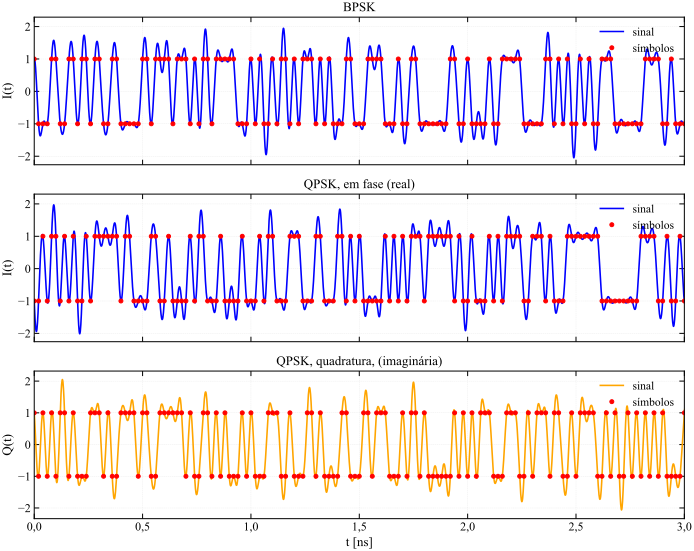

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from simcopy.plotting import apply_style, density_map
apply_style()          # estilo das figuras: guia de figuras do TCC (src/simcopy/plotting.py)

from simcopy.kernels.pulse_shaping import raised_cosine_response, shape_pulses

#Generator
def generate_binary_data(n_bits: int, seed: int = 1) -> np.ndarray:
    """
    Generate an array of bits
    Args:
        n_bits (int)
        seed (int): semente (a mesma semente dá a mesma sequência)
    Returns:
        np.ndarray
    """
    rng = np.random.default_rng(seed)
    return rng.integers(0, 2, n_bits)

def map_bpsk(bits: np.ndarray) -> np.ndarray:
    """
    Map bits to BPSK symbols (0 -> +1, 1 -> -1)
    Args:
        bits (np.ndarray): um bit por símbolo
    Returns:
        np.ndarray: símbolos complexos
    """
    return (1 - 2 * bits).astype(complex)

def map_qpsk(bits: np.ndarray) -> np.ndarray:
    """
    Map pairs of bits to QPSK symbols (Gray)
    Args:
        bits (np.ndarray): dois bits por símbolo. O primeiro escolhe Q e o segundo escolhe I
    Returns:
        np.ndarray: símbolos complexos (+-1 +-1j)
    """
    pairs = bits.reshape(-1, 2)
    return (1 - 2 * pairs[:, 1]) + 1j * (1 - 2 * pairs[:, 0])

def nyquist_filter(symbols: np.ndarray, sps: int, fs: float, symbol_rate: float, rolloff: float) -> np.ndarray:
    """
    Apply the raised cosine (Nyquist) pulse shaping
    Args:
        symbols (np.ndarray): símbolos complexos
        sps (int): amostras por símbolo
        fs (float): taxa de amostragem [Hz]
        symbol_rate (float): taxa de símbolos [Hz]
        rolloff (float): fator de rolloff
    Returns:
        np.ndarray: sinal I(t) + iQ(t), array of shape (len(symbols) * sps,)
    """
    freq = np.fft.fftfreq(symbols.size * sps, 1 / fs)
    return shape_pulses(symbols, sps, raised_cosine_response(freq, symbol_rate, rolloff))

n_symbols = 4096
sps = 16
Rs = 50e9                 # taxa de símbolos
fs = Rs * sps             # taxa de amostragem
rolloff = 0.18

bpsk_bits = generate_binary_data(n_symbols)
qpsk_bits = generate_binary_data(2 * n_symbols)
bpsk_symbols = map_bpsk(bpsk_bits)
qpsk_symbols = map_qpsk(qpsk_bits)
bpsk_signal = nyquist_filter(bpsk_symbols, sps, fs, Rs, rolloff)
qpsk_signal = nyquist_filter(qpsk_symbols, sps, fs, Rs, rolloff)

time = np.arange(n_symbols * sps) / fs
centers = np.arange(n_symbols) * sps       # amostra do centro de cada símbolo

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(time * 1e9, bpsk_signal.real, label="sinal")
ax[0].plot(time[centers] * 1e9, bpsk_symbols.real, "o", ms=4, label="símbolos")
ax[0].set(ylabel="I(t)", title="BPSK")
ax[1].plot(time * 1e9, qpsk_signal.real, label="sinal")
ax[1].plot(time[centers] * 1e9, qpsk_symbols.real, "o", ms=4, label="símbolos")
ax[1].set(ylabel="I(t)", title="QPSK, em fase (real)")
ax[2].plot(time * 1e9, qpsk_signal.imag, color="orange", label="sinal")
ax[2].plot(time[centers] * 1e9, qpsk_symbols.imag, "o", ms=4, color="red", label="símbolos")
ax[2].set(xlabel="t [ns]", ylabel="Q(t)", title="QPSK, quadratura, (imaginária)", xlim=(0, 3))
for a in ax:
    a.legend(loc="upper right")
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Ajuste do sinal ao simcopy

Como no notebook 07, o sinal precisa ser embalado em `Waveform`, com domínio, geometria e escala de tempo. O sinal elétrico do coerente é complexo: a parte real é I(t) e a imaginária é Q(t).

O bloco `NyquistDriver` do simcopy faz o mapeamento e o pulso de uma vez. Abaixo conferimos que ele dá o mesmo sinal.

diferença máxima para o NyquistDriver (BPSK): 0.0
diferença máxima para o NyquistDriver (QPSK): 0.0


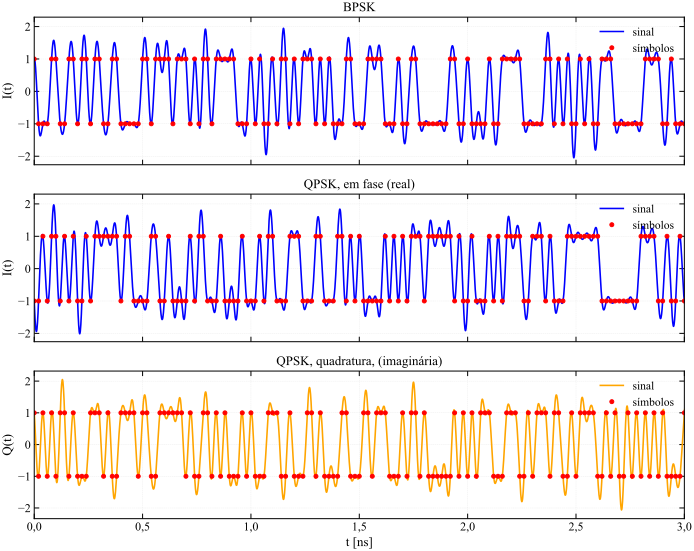

In [19]:
from simcopy.components.tx.iq_driver import NyquistDriver
from simcopy.core.context import SimContext
from simcopy.core.grid import TimeGrid
from simcopy.core.signals import Bits, Domain, SignalGeometry, Waveform
from simcopy.core.units import C_LIGHT

f0 = C_LIGHT / 1550e-9    # frequência do canal

centers = np.arange(n_symbols) * sps       # amostra do centro de cada símbolo

grid = TimeGrid(fs, n_symbols * sps)
ctx = SimContext(grid=grid, root_seed=1)
bpsk_geometry = SignalGeometry(n_symbols=n_symbols, bits_per_symbol=1, samples_per_symbol=sps, n_pol=1)
qpsk_geometry = SignalGeometry(n_symbols=n_symbols, bits_per_symbol=2, samples_per_symbol=sps, n_pol=1)

# o mesmo pelo bloco do simcopy
bpsk_drive = NyquistDriver(Rs, "BPSK", rolloff, channel_id=0)(Bits(bpsk_bits[None, :].astype(np.uint8), bpsk_geometry), ctx)
qpsk_drive = NyquistDriver(Rs, "QPSK", rolloff, channel_id=0)(Bits(qpsk_bits[None, :].astype(np.uint8), qpsk_geometry), ctx)
print("diferença máxima para o NyquistDriver (BPSK):", np.abs(bpsk_drive.samples[0] - bpsk_signal).max())
print("diferença máxima para o NyquistDriver (QPSK):", np.abs(qpsk_drive.samples[0] - qpsk_signal).max())
bpsk_symbols = map_bpsk(bpsk_bits)
qpsk_symbols = map_qpsk(qpsk_bits)

fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(grid.time * 1e9, bpsk_drive.samples[0].real, label="sinal")
ax[0].plot(grid.time[centers] * 1e9, bpsk_symbols.real, "o", ms=4, label="símbolos")
ax[0].set(ylabel="I(t)", title="BPSK")
ax[1].plot(grid.time * 1e9, qpsk_drive.samples[0].real, label="sinal")
ax[1].plot(grid.time[centers] * 1e9, qpsk_symbols.real, "o", ms=4, label="símbolos")
ax[1].set(ylabel="I(t)", title="QPSK, em fase (real)")
ax[2].plot(grid.time * 1e9, qpsk_drive.samples[0].imag, color="orange", label="sinal")
ax[2].plot(grid.time[centers] * 1e9, qpsk_symbols.imag, "o", ms=4, color="red", label="símbolos")
ax[2].set(xlabel="t [ns]", ylabel="Q(t)", title="QPSK, quadratura, (imaginária)", xlim=(0, 3))
for a in ax:
    a.legend(loc="upper right")
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## BPSK: laser e MZM

O MZM em push-pull tem transmissão de campo $\cos[\pi(2V - V_b)/(2V_\pi)]$ (Agrawal, Eq. 10.1.4 e 10.1.5). No IMDD polarizamos na quadratura ($V_b = V_\pi/2$). Aqui polarizamos no nulo ($V_b = V_\pi$), onde o campo é $\sin(\pi V/V_\pi)$: ele troca de sinal com a tensão. O campo continua real, porém pode ser ou positivo ou negativo, ou seja, com fase 0 ou π.

A tensão passa pela pré-distorção $V = (V_\pi/\pi)\arcsin(m\,s)$, que deixa o campo proporcional ao sinal: campo $= m\,s$. Usamos $m = 0{,}4$, para o pico do sinal entre os símbolos não passar de 1.

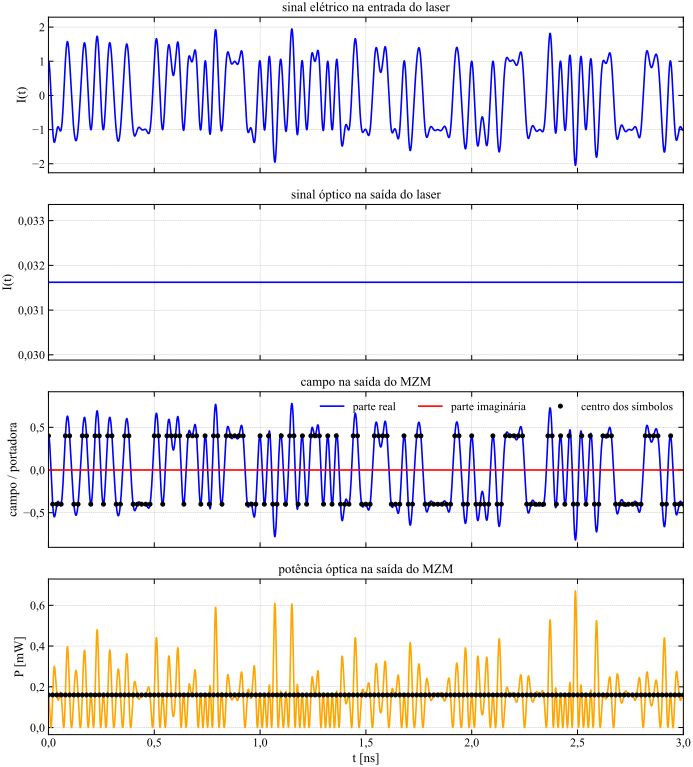

In [20]:
from simcopy.components.tx.laser import CWLaser
from simcopy.config.system import CWLaserConfig
from simcopy.kernels.modulator.mzm import arcsin_predistortion, mzm_field, push_pull

# passar pelo laser: portadora de 1 mW, com ruído de fase (largura de linha de 500 kHz)
laser = CWLaser(CWLaserConfig(power=1e-3, linewidth=500e3), f0)
carrier = laser(bpsk_drive, ctx) # bpsk_drive só é usado para definir grid, canal e geometria

# passar pelo mzm, polarizado no nulo
vpi = 5.0
depth = 0.4                                                                # excursão do campo nos símbolos
voltage = arcsin_predistortion(bpsk_drive.samples[0].real, vpi, depth)     # pré-distorção
v1, v2 = push_pull(voltage, vpi)                                           # V_b = V_pi
bpsk_field = mzm_field(carrier.samples[0], v1, v2, vpi)

# o que o MZM fez com a portadora (tira o ruído de fase do laser)
modulation = bpsk_field / carrier.samples[0]

fig, ax = plt.subplots(4, 1, figsize=(10, 11), sharex=True)
ax[0].plot(time * 1e9, bpsk_drive.samples[0].real)
ax[0].set(ylabel="I(t)", title="sinal elétrico na entrada do laser")
ax[1].plot(time * 1e9, np.abs(carrier.samples[0]))
ax[1].set(ylabel="I(t)", title="sinal óptico na saída do laser")
ax[2].plot(time * 1e9, modulation.real, label="parte real")
ax[2].plot(time * 1e9, modulation.imag, label="parte imaginária")
ax[2].plot(time[centers] * 1e9, modulation[centers].real, "o", ms=4, color="k", label="centro dos símbolos")
ax[2].set(ylabel="campo / portadora", title="campo na saída do MZM")
ax[2].legend(loc="upper right", ncol=3)
ax[3].plot(time * 1e9, np.abs(bpsk_field) ** 2 * 1e3, color="orange")
ax[3].plot(time[centers] * 1e9, np.abs(bpsk_field[centers]) ** 2 * 1e3, "o", ms=4, color="k")
ax[3].set(xlabel="t [ns]", ylabel="P [mW]", title="potência óptica na saída do MZM", xlim=(0, 3))
plt.tight_layout()
plt.show()

O campo dividido pela portadora é real, pois o MZM só está mudando a amplitude. No centro dos símbolos, o campo replica o corportamento visto na onda elétrica, de Nyquist. A potência óptica no centro dos símbolos é sempre a mesma, então ela não pode ser usada para analisar o sinal, assim como fizemos com OOK/IMDD.

## Modulador IQ e fotodetector direto

O segundo passo é o modulador em quadratura (Agrawal, Fig. 10.3), que nada mais é do que um MZM no nulo para I(t), outro para Q(t), e uma defasagem de π/2 entre os dois braços. O campo de saída é $\tfrac{1}{2}[t_I + i\,t_Q]$ vezes a portadora. Com isso, ao invés de modularmos somente a amplitude, também modulamos a fase, cobrindo o plano complexo. No simcopy é o bloco `IQModulator`, que recebe a portadora e o sinal elétrico.

Na saída colocamos só um fotodetector, como no IMDD. Ele mede $|E|^2 = I^2 + Q^2$. Se I e Q têm dois níveis (±1, o "OOK" da aula), $|E|^2$ é constante no centro dos símbolos: a fase se perde.

potência no centro dos símbolos: média = 0.0800 mW, desvio relativo = 7.5e-16
potência entre os símbolos: de 0.0000 a 0.3004 mW


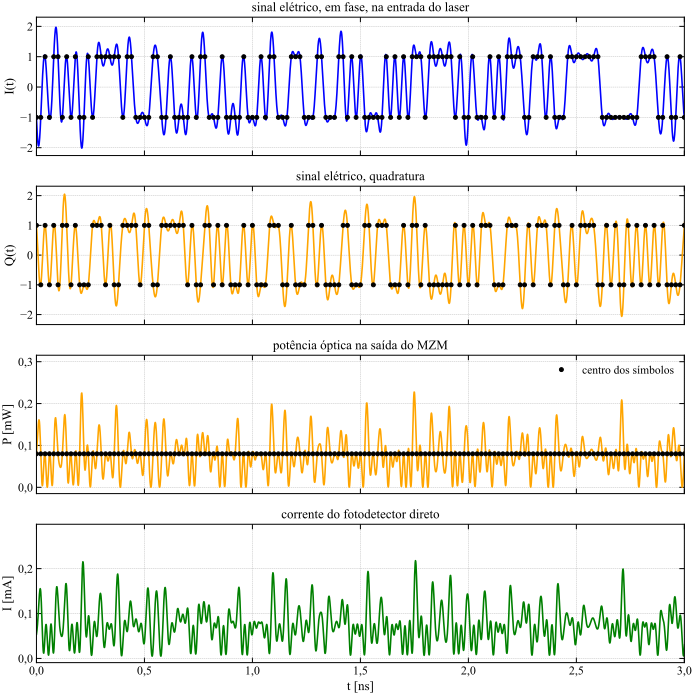

In [21]:
from simcopy.components.rx.photodiode import Photodiode
from simcopy.components.tx.iq_modulator import IQModulator
from simcopy.config.system import MZMConfig, PhotodiodeConfig

# modulador IQ ideal, sem perda de inserção e com extinção infinita
mzm_config = MZMConfig(vpi=vpi, insertion_loss_db=0.0, extinction_ratio_db=np.inf)
iq_modulator = IQModulator(mzm_config, drive_depth=depth)
qpsk_carrier = laser(qpsk_drive, ctx)
qpsk_waveform = iq_modulator([qpsk_carrier, qpsk_drive], ctx)

# fotodetector direto, sem ruído, para ver a corrente
quiet_photodiode = PhotodiodeConfig(responsivity=1.0, thermal_noise_density=0.0, shot_noise=False)
direct_current = Photodiode(quiet_photodiode, Rs)(qpsk_waveform, ctx)

qpsk_power = np.abs(qpsk_waveform.samples[0]) ** 2
print(f"potência no centro dos símbolos: média = {qpsk_power[centers].mean() * 1e3:.4f} mW, "
      f"desvio relativo = {qpsk_power[centers].std() / qpsk_power[centers].mean():.1e}")
print(f"potência entre os símbolos: de {qpsk_power.min() * 1e3:.4f} a {qpsk_power.max() * 1e3:.4f} mW")

fig, ax = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
ax[0].plot(time * 1e9, qpsk_drive.samples[0].real)
ax[0].plot(time[centers] * 1e9, qpsk_symbols.real, "o", ms=4, color="k")
ax[0].set(ylabel="I(t)", title="sinal elétrico, em fase, na entrada do laser")
ax[1].plot(time * 1e9, qpsk_drive.samples[0].imag, color="orange")
ax[1].plot(time[centers] * 1e9, qpsk_symbols.imag, "o", ms=4, color="k")
ax[1].set(ylabel="Q(t)", title="sinal elétrico, quadratura")
ax[2].plot(time * 1e9, qpsk_power * 1e3, color="orange")
ax[2].plot(time[centers] * 1e9, qpsk_power[centers] * 1e3, "o", ms=4, color="k", label="centro dos símbolos")
ax[2].set(ylabel="P [mW]", title="potência óptica na saída do MZM")
ax[2].legend(loc="upper right")
ax[3].plot(time * 1e9, direct_current.samples[0].real * 1e3, color="green")
ax[3].set(xlabel="t [ns]", ylabel="I [mA]", title="corrente do fotodetector direto", xlim=(0, 3))
plt.tight_layout()
plt.show()

O fotodetector ideal tem a mesma saída que o MZM, porém em corrente. Isso significa que precisamos de um passo adicional para recuperar o sinal elétrico do transmissor, pois o sinal recebido está modulado.

## Oscilador local

Se colocarmos um laser no receptor, antes do fotodetector, temos um oscilador local (LO). Somando os dois campos num acoplador, a potência no fotodetector é (Agrawal, Eq. 4.5.3)

$$P(t) = P_s + P_{LO} + 2\sqrt{P_s P_{LO}}\,\cos(\omega_{IF}t + \phi_s - \phi_{LO})$$

O último termo é o batimento, e carrega a fase do sinal. Aqui o oscilador local é uma cópia do laser do transmissor (bloco `LockedLocalOscillator`): mesma frequência e mesma fase. Para realizar a operação acima, também precisamos de um acoplador (no nosso caso, uma híbrida, e seu comportamento será explicado em breve) e um fotodetector.

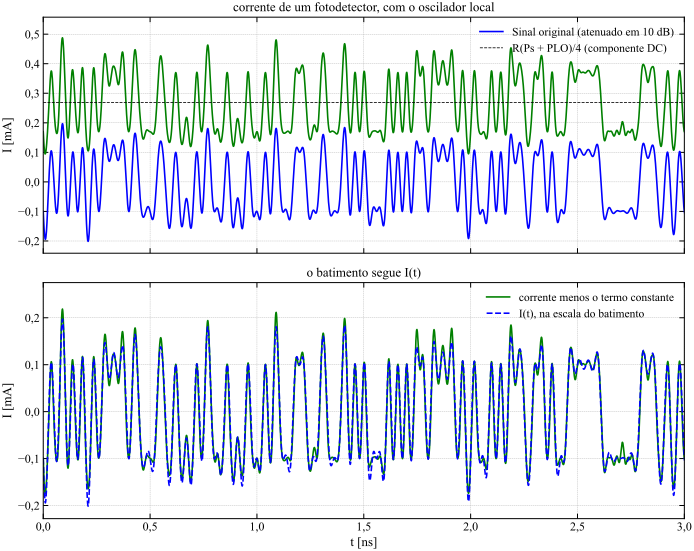

In [22]:
from simcopy.components.rx.coherent import LockedLocalOscillator
from simcopy.kernels.coherent import hybrid_90
from simcopy.kernels.photodetector import photocurrent

# LO
lo_power = 1e-3
lo = LockedLocalOscillator(power=lo_power)(qpsk_carrier, ctx)

ports = hybrid_90(qpsk_waveform.samples[0], lo.samples[0])      # híbrida
single_current = photocurrent(ports[:1], 1.0)                   # fotodetector

# Eq. 4.5.3
constant_term = 0.25 * (qpsk_power.mean() + lo_power)
beat_term = 0.5 * np.real(qpsk_waveform.samples[0] * np.conj(lo.samples[0]))

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
ax[0].plot(time * 1e9, single_current * 1e3, color="green")
ax[0].plot(time * 1e9, qpsk_drive.samples[0].real/10, color="blue", label="Sinal original (atenuado em 10 dB)")
ax[0].axhline(constant_term * 1e3, color="k", ls="--", lw=0.8, label="R(Ps + PLO)/4 (componente DC)")
ax[0].set(ylabel="I [mA]", title="corrente de um fotodetector, com o oscilador local")
ax[0].legend(loc="upper right")
ax[1].plot(time * 1e9, (single_current - constant_term) * 1e3, color="green", label="corrente menos o termo constante")
ax[1].plot(time * 1e9, qpsk_drive.samples[0].real * beat_term[centers].std() * 1e3, "--", color="blue", label="I(t), na escala do batimento")
ax[1].set(ylabel="I [mA]", title="o batimento segue I(t)")
ax[1].legend(loc="upper right")
ax[1].set(xlabel="t [ns]", xlim=(0, 3))
plt.tight_layout()
plt.show()

Com um fotodetector só recuperamos uma quadratura, e ainda somada ao termo constante e a $P_s(t)$, que varia entre os símbolos (é a pequena diferença entre as duas curvas do painel do meio). Para o QPSK, metade da informação continua perdida.

## Híbrida de 90° e detecção balanceada

O último passo usa as quatro saídas da híbrida de 90°:

$$E_{1,2} = \tfrac{1}{2}(E_s \pm E_{LO}), \qquad E_{3,4} = \tfrac{1}{2}(E_s \pm i\,E_{LO})$$

com um fotodetector em cada uma. No receptor balanceado as correntes são extraídas duas a duas (Agrawal, Eq. 10.2.4), dessa forma o termo constante some e sobra só o batimento,

$$I_1 - I_2 = R\,\mathrm{Re}[E_s E_{LO}^*], \qquad I_3 - I_4 = R\,\mathrm{Im}[E_s E_{LO}^*]$$

ou seja, $I + iQ = R\,E_s E_{LO}^*$, o campo do sinal, com a fase medida em relação ao oscilador local. No simcopy é o bloco `CoherentFrontEnd`, que também põe o ruído de cada fotodetector e o filtro do receptor.

sem filtro: instante de decisão = 0 amostras | EVM = 0.00 % | erros = 0/8148


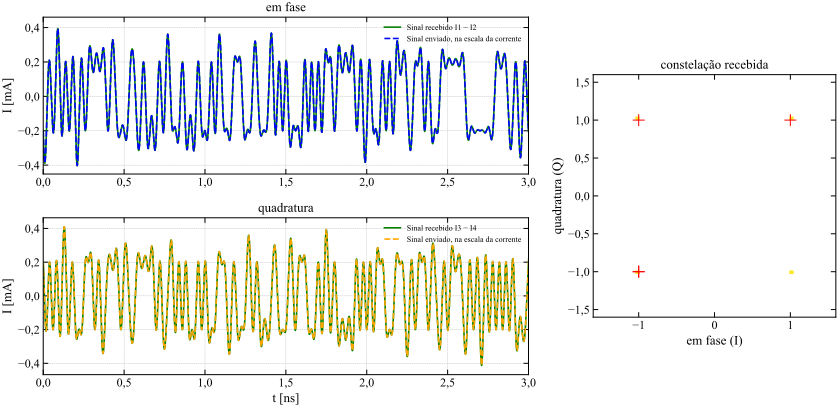

In [23]:
from simcopy.kernels.demodulation import measure_coherent, sample_symbols

# primeiro sem o filtro do receptor, sem ruído
hybrid_currents = np.array([photocurrent(port[None, :], 1.0) for port in ports])
no_filter_current = (hybrid_currents[0] - hybrid_currents[1]) + 1j * (hybrid_currents[2] - hybrid_currents[3])
no_filter_measure = measure_coherent(no_filter_current, qpsk_bits, "QPSK", sps, guard=11)
no_filter_received = sample_symbols(no_filter_current, sps, no_filter_measure.delay, no_filter_measure.first_symbol, no_filter_measure.last_symbol)
no_filter_received = no_filter_received / (no_filter_measure.gain * np.exp(1j * no_filter_measure.phase))
print(f"sem filtro: instante de decisão = {no_filter_measure.delay} amostras | EVM = {100 * no_filter_measure.evm:.2f} % | "
      f"erros = {no_filter_measure.errors}/{no_filter_measure.n_bits}")

fig = plt.figure(figsize=(12, 6))
grid_spec = fig.add_gridspec(2, 2, width_ratios=[2, 1])
ax_i, ax_q, ax_c = fig.add_subplot(grid_spec[0, 0]), fig.add_subplot(grid_spec[1, 0]), fig.add_subplot(grid_spec[:, 1])
ax_i.plot(time * 1e9, no_filter_current.real * 1e3, color="green", label="Sinal recebido I1 − I2")
ax_i.plot(time * 1e9, np.roll(qpsk_drive.samples[0].real, no_filter_measure.delay) * no_filter_measure.gain * 1e3, "--", color="blue", label="Sinal enviado, na escala da corrente")
ax_i.set(ylabel="I [mA]", title="em fase", xlim=(0, 3))
ax_q.plot(time * 1e9, no_filter_current.imag * 1e3, color="green", label="Sinal recebido I3 − I4")
ax_q.plot(time * 1e9, np.roll(qpsk_drive.samples[0].imag, no_filter_measure.delay) * no_filter_measure.gain * 1e3, "--", color="orange", label="Sinal enviado, na escala da corrente")
ax_q.set(xlabel="t [ns]", ylabel="I [mA]", title="quadratura", xlim=(0, 3))
for a in (ax_i, ax_q):
    a.legend(loc="upper right", fontsize=8)
density_map(ax_c, no_filter_received, lim=1.6)
ax_c.plot(qpsk_symbols.real[:4], qpsk_symbols.imag[:4], "+", color="red", ms=12)
ax_c.set(xlabel="em fase (I)", ylabel="quadratura (Q)", title="constelação recebida", xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect="equal")
plt.tight_layout()
plt.show()

Sem o filtro do receptor, a corrente é exatamente $R\,E_s E_{LO}^*$. O instante de decisão é o centro do símbolo (0 amostras) e a EVM (métrica de erro) é nula, porque o pulso de Nyquist do transmissor não deixa interferência entre os símbolos nos centros, e o receptor não afeta o sinal de nenhum modo. Agora o mesmo sinal passa pelo bloco `CoherentFrontEnd`, que inclui o filtro do receptor.

instante de decisão = 5 amostras | EVM = 3.63 % | erros = 0/8148


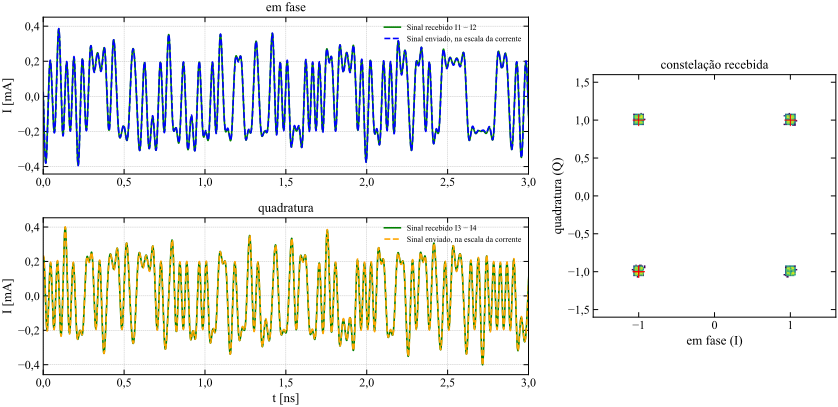

In [24]:
from simcopy.components.rx.coherent import CoherentFrontEnd
from simcopy.kernels.demodulation import measure_coherent, sample_symbols

# mesma coisa, mas via simcopy
# aqui o receptor possui um filtro, que atrasa e distorce o sinal
frontend = CoherentFrontEnd(quiet_photodiode, Rs)
iq_current = frontend([qpsk_waveform, lo], ctx) # aqui obtemos um array complexo
measure = measure_coherent(iq_current.samples[0], qpsk_bits, "QPSK", sps, guard=11)
received = sample_symbols(iq_current.samples[0], sps, measure.delay, measure.first_symbol, measure.last_symbol)
received = received / (measure.gain * np.exp(1j * measure.phase))
print(f"instante de decisão = {measure.delay} amostras | EVM = {100 * measure.evm:.2f} % | erros = {measure.errors}/{measure.n_bits}")

fig = plt.figure(figsize=(12, 6))
grid_spec = fig.add_gridspec(2, 2, width_ratios=[2, 1])
ax_i, ax_q, ax_c = fig.add_subplot(grid_spec[0, 0]), fig.add_subplot(grid_spec[1, 0]), fig.add_subplot(grid_spec[:, 1])
ax_i.plot(time * 1e9, iq_current.samples[0].real * 1e3, color="green", label="Sinal recebido I1 − I2")
ax_i.plot(time * 1e9, np.roll(qpsk_drive.samples[0].real, measure.delay) * measure.gain * 1e3, "--", color="blue", label="Sinal enviado, na escala da corrente")
ax_i.set(ylabel="I [mA]", title="em fase", xlim=(0, 3))
ax_q.plot(time * 1e9, iq_current.samples[0].imag * 1e3, color="green", label="Sinal recebido I3 − I4")
ax_q.plot(time * 1e9, np.roll(qpsk_drive.samples[0].imag, measure.delay) * measure.gain * 1e3, "--", color="orange", label="Sinal enviado, na escala da corrente")
ax_q.set(xlabel="t [ns]", ylabel="I [mA]", title="quadratura", xlim=(0, 3))
for a in (ax_i, ax_q):
    a.legend(loc="upper right", fontsize=8)
density_map(ax_c, received, lim=1.6, bins=200)
ax_c.plot(qpsk_symbols.real[:4], qpsk_symbols.imag[:4], "+", color="red", ms=12)
ax_c.set(xlabel="em fase (I)", ylabel="quadratura (Q)", title="constelação recebida", xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect="equal")
plt.tight_layout()
plt.show()

A EVM (medida de magnitude de erro de um vetor) passou de 0 % para 3,6 % por causa do filtro do receptor, um filtro de Bessel de ordem 4 com 11,5 GHz. O filtro atrasa o sinal em cerca de 29 ps, ou 4,7 amostras de 6,25 ps. O simcopy, por conhecer os símbolos transmitidos, ajusta o instante de decisão para 5 amostras depois do centro do símbolo. Como o atraso real é 4,7, sobra 0,3 amostra de erro no instante de decisão. Com o atraso fracionário certo a EVM cai para 1,9 %.

Um receptor real não tem os símbolos transmitidos e precisaria recuperar o relógio sem eles, o que ainda não existe no simcopy.

## BER: contar erros, fator Q e EVM

No IMDD a BER de interesse é muito baixa e usamos o fator Q no lugar da contagem. No coerente o sistema trabalha com BER perto de $10^{-3}$ antes do código corretor de erros, então calculamos a BER contando os erros.

Daqui em diante usamos o simcopy com arquivo de configuração:
- `examples/coerente_bpsk.yaml`: BPSK, com −44 dBm na entrada do receptor
- `examples/coerente_qpsk.yaml`: QPSK, com −41 dBm

Nos dois, o laser e o oscilador local têm 1 mW, o oscilador local é a cópia do laser do transmissor (`lo_source: tx_laser`), e cada fotodetector tem ruído de disparo e ruído térmico de 10 pA/√Hz. São $2^{15}$ símbolos.

O `run` monta os blocos, roda e mede. A medida do coerente:
- acha o instante dos símbolos pela correlação entre a corrente e os símbolos transmitidos (que o simulador conhece)
- tira a escala e uma rotação constante com um ganho complexo
- decide cada símbolo pelo ponto mais próximo e conta os erros
- calcula a EVM, que é o desvio rms dos pontos recebidos em relação aos ideais
- calcula o fator Q: no BPSK e no QPSK cada bit é uma decisão entre dois níveis numa quadratura, e vale a mesma conta do IMDD, $Q = (I_1 - I_0)/(\sigma_1 + \sigma_0)$ e $\mathrm{BER} = \tfrac{1}{2}\mathrm{erfc}(Q/\sqrt{2})$ (Agrawal, Eq. 10.3.2 e 10.3.7)

estágios: ['ch0.tx.bits', 'ch0.tx.driver', 'ch0.tx.laser', 'ch0.tx.modulator', 'ch0.tx.power', 'ch0.rx.lo', 'ch0.rx.frontend']
BPSK: canal 0: BER contada = 1.222e-03 (40/32746) | EVM = 46.61 % (SNR = 6.63 dB) | Q = 3.033 | BER por Q = 1.209e-03 | potencia recebida = -44.00 dBm | instante = 5 amostras | simbolos 11 a 32756 | MI = 0.995, GMI = 0.995 bits/simbolo
QPSK: canal 0: BER contada = 1.451e-03 (95/65492) | EVM = 33.09 % (SNR = 9.61 dB) | Q = 3.023 | BER por Q = 1.253e-03 | potencia recebida = -41.00 dBm | instante = 5 amostras | simbolos 11 a 32756 | MI = 1.989, GMI = 1.989 bits/simbolo


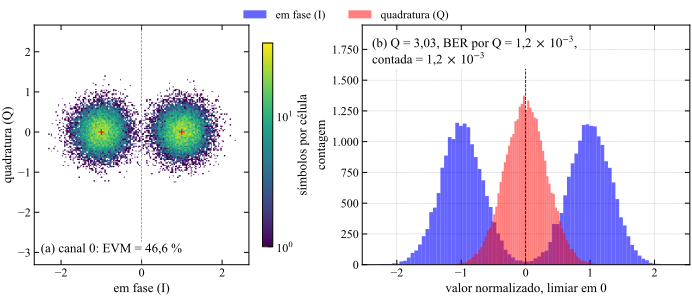

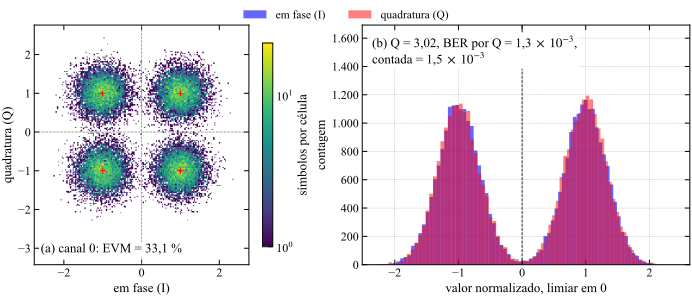

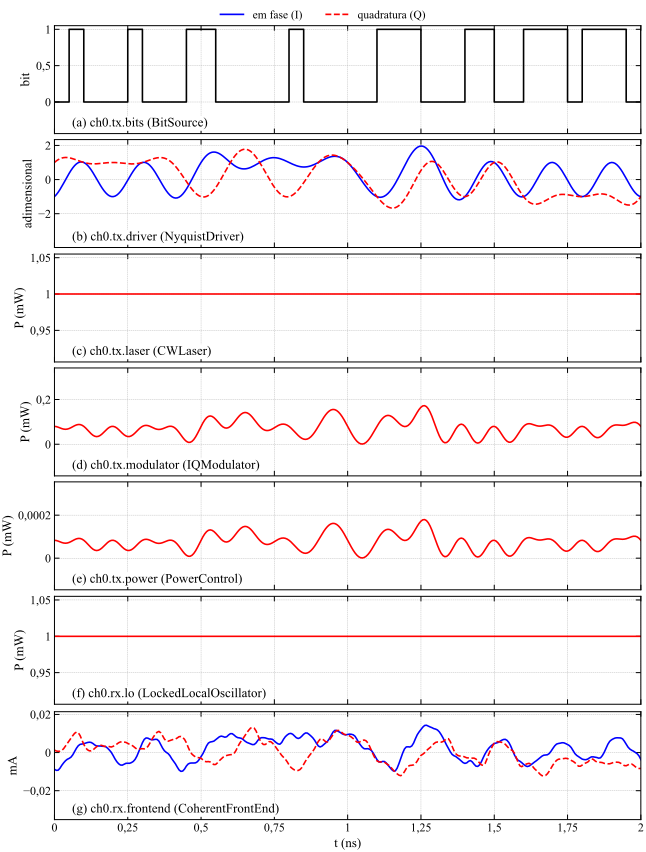

In [25]:
from pathlib import Path

import simcopy
from simcopy.config.io import load
from simcopy.core.units import dbm_to_w, w_to_dbm
from simcopy.pipelines.runner import run, sweep
from simcopy.plotting import plot_chain, plot_constellation

# os exemplos ficam na raiz do repositório, qualquer que seja a pasta em que o notebook roda
examples = Path(simcopy.__file__).parents[2] / "examples"

bpsk_system, bpsk_simulation = load(examples / "coerente_bpsk.yaml")
qpsk_system, qpsk_simulation = load(examples / "coerente_qpsk.yaml")

bpsk = run(bpsk_system, bpsk_simulation)
qpsk = run(qpsk_system, qpsk_simulation)
print("estágios:", qpsk.ids)
print("BPSK:", bpsk.summary())
print("QPSK:", qpsk.summary())

plot_constellation(bpsk)
plot_constellation(qpsk)
plot_chain(qpsk)            # um painel por estágio
plt.show()

BPSK a −44 dBm: 40 erros em 32746 bits (1,22e-3), e Q = 3,03 dá 1,21e-3. QPSK a −41 dBm: 95 erros em 65492 bits (1,45e-3), e Q = 3,02 dá 1,25e-3, que são 82 erros esperados, com desvio de 9. A contagem e o fator Q concordam dentro do erro estatístico.

Para a mesma BER o QPSK precisa de 3 dB a mais de potência, e leva o dobro de bits por símbolo: a energia por bit é a mesma. A EVM do BPSK (47 %) é maior que a do QPSK (33 %) com a mesma BER, porque no BPSK o ruído da quadratura que não decide nada também entra na EVM.

## BER pela potência recebida

Variamos a potência na entrada do receptor e comparamos três valores: a BER contada, a BER pelo fator Q e a BER pela conta do ruído.

A conta do ruído (Agrawal, Eq. 4.5.9 e 4.5.10, somando os quatro fotodetectores):

$$\sigma^2 = 4\,i_T^2\,\Delta f + 2qR\,(P_{LO} + P_s)\,\Delta f$$

com $i_T$ a densidade do ruído térmico de cada fotodetector e $\Delta f$ a banda equivalente de ruído do filtro do receptor. A potência elétrica do sinal no centro dos símbolos é $R^2 P_{LO} P_s\,\eta^2/(1 - \rho/4)$. O fator $(1 - \rho/4)$ é a razão entre a potência média do sinal com pulso de Nyquist e a potência no centro dos símbolos (medimos 0,956 na primeira seção). O fator $\eta$ é o pico de um pulso depois do filtro do receptor, que o filtro reduz um pouco. A SNR é a razão entre as duas potências, e

$$Q = \sqrt{2\,\mathrm{SNR}/k}, \qquad \mathrm{BER} = \tfrac{1}{2}\mathrm{erfc}(Q/\sqrt{2})$$

com $k$ o número de bits por símbolo (1 no BPSK, 2 no QPSK).

banda equivalente de ruído do filtro do receptor = 55.04 GHz
pico de um pulso depois do filtro = 4.8955
 formato | P [dBm] | SNR [dB] |  contada  erros |  por Q    | conta do ruído
   BPSK  |   -50.0 |     0.66 |  6.38e-02  2089 |  6.31e-02 |  6.40e-02
   BPSK  |   -49.0 |     1.65 |  4.28e-02  1402 |  4.32e-02 |  4.39e-02
   BPSK  |   -48.0 |     2.65 |  2.64e-02   865 |  2.73e-02 |  2.77e-02
   BPSK  |   -47.0 |     3.65 |  1.56e-02   512 |  1.56e-02 |  1.58e-02
   BPSK  |   -46.0 |     4.64 |  8.09e-03   265 |  7.85e-03 |  7.94e-03
   BPSK  |   -45.0 |     5.64 |  3.54e-03   116 |  3.39e-03 |  3.40e-03
   BPSK  |   -44.0 |     6.63 |  1.22e-03    40 |  1.21e-03 |  1.20e-03
   BPSK  |   -43.0 |     7.62 |  4.58e-04    15 |  3.40e-04 |  3.29e-04
   BPSK  |   -42.0 |     8.61 |  6.11e-05     2 |  7.12e-05 |  6.61e-05
   BPSK  |   -41.0 |     9.60 |  0.00e+00     0 |  1.04e-05 |  8.98e-06
   QPSK  |   -47.0 |     3.66 |  6.38e-02  4180 |  6.38e-02 |  6.43e-02
   QPSK  |   -46.0 |     4.

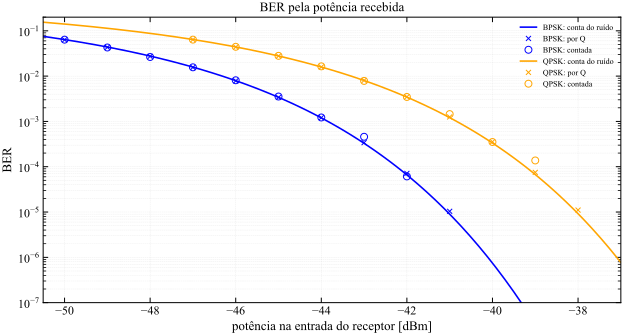

In [26]:
from scipy.special import erfc

from simcopy.core.units import Q_ELECTRON
from simcopy.kernels.filters import lowpass_response, noise_bandwidth

def predicted_ber(system, result, received_power):
    """
    BER pela conta do ruído do receptor coerente
    Args:
        system: configuração do sistema (um canal coerente)
        result: um resultado desse sistema (dá a grade da simulação)
        received_power (np.ndarray): potência na entrada do receptor [W]
    Returns:
        np.ndarray: BER
    """
    channel = system.channels[0]
    pd, lo_power = channel.rx.photodiode, channel.rx.lo.power
    freq = result.resolved.grid.freq
    response = lowpass_response(freq, pd.bandwidth_factor * channel.symbol_rate, pd.filter_type, pd.filter_order)
    delta_f = noise_bandwidth(response, freq)
    # pico de um pulso de Nyquist depois do filtro do receptor (1 sem o filtro)
    sps = result.resolved.channels[0].samples_per_symbol
    one_symbol = np.zeros(freq.size // sps, dtype=complex)
    one_symbol[0] = 1.0
    nyquist = raised_cosine_response(freq, channel.symbol_rate, channel.tx.rolloff)
    pulse_peak = np.abs(shape_pulses(one_symbol, sps, nyquist * response)).max()
    noise =4 * pd.thermal_noise_density ** 2 * delta_f \
        + 2 * Q_ELECTRON * pd.responsivity * (lo_power + received_power) * delta_f
    signal = pd.responsivity ** 2 * lo_power * received_power * pulse_peak ** 2 / (1 - channel.tx.rolloff / 4)
    q = np.sqrt(2 * signal / noise / channel.modulation.bits_per_symbol)
    return 0.5 * erfc(q / np.sqrt(2))

freq = qpsk.resolved.grid.freq
response = lowpass_response(freq, 1.15 * Rs, "bessel", 4)
one_symbol = np.zeros(freq.size // 16, dtype=complex)
one_symbol[0] = 1.0
print(f"banda equivalente de ruído do filtro do receptor = {noise_bandwidth(response, freq) / 1e9:.2f} GHz")
print(f"pico de um pulso depois do filtro = {np.abs(shape_pulses(one_symbol, 16, raised_cosine_response(freq, Rs, rolloff) * response)).max():.4f}")

# a mesma realização de ruído em todos os pontos. O transmissor roda uma vez só
bpsk_powers_dbm = np.arange(-50.0, -40.5, 1.0)
qpsk_powers_dbm = np.arange(-47.0, -37.5, 1.0)
bpsk_sweep = sweep(bpsk_system, bpsk_simulation, "channels[0].launch_power", dbm_to_w(bpsk_powers_dbm))
qpsk_sweep = sweep(qpsk_system, qpsk_simulation, "channels[0].launch_power", dbm_to_w(qpsk_powers_dbm))

print(" formato | P [dBm] | SNR [dB] |  contada  erros |  por Q    | conta do ruído")
for name, system, result, powers, s in (("BPSK", bpsk_system, bpsk, bpsk_powers_dbm, bpsk_sweep),
                                         ("QPSK", qpsk_system, qpsk, qpsk_powers_dbm, qpsk_sweep)):
    theory = predicted_ber(system, result, dbm_to_w(powers))
    for k, p in enumerate(powers):
        m = s.metrics[k][0]
        print(f"   {name}  | {p:7.1f} | {m.snr_db:8.2f} | {m.ber_counted:9.2e} {m.errors:5d} | {m.ber_q:9.2e} | {theory[k]:9.2e}")

fig, ax = plt.subplots(1, 1, figsize=(9, 5))
fine = np.linspace(-50.5, -37.0, 200)
for name, system, result, powers, s, color in (("BPSK", bpsk_system, bpsk, bpsk_powers_dbm, bpsk_sweep, "blue"),
                                                ("QPSK", qpsk_system, qpsk, qpsk_powers_dbm, qpsk_sweep, "orange")):
    ax.semilogy(fine, predicted_ber(system, result, dbm_to_w(fine)), color=color, label=f"{name}: conta do ruído")
    ax.semilogy(powers, s.metric("ber_q"), "x", color=color, label=f"{name}: por Q")
    counted = s.metric("errors") > 0
    ax.semilogy(powers[counted], s.metric("ber_counted")[counted], "o", mfc="none", ms=7, color=color, label=f"{name}: contada")
ax.set(xlabel="potência na entrada do receptor [dBm]", ylabel="BER", ylim=(1e-7, 0.2), xlim=(-50.5, -37.0),
       title="BER pela potência recebida")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

As três BER andam juntas. Onde há muitos erros, a contada, a de Q e a da conta do ruído diferem em poucos por cento: no BPSK a −46 dBm, 8,1e-3, 7,9e-3 e 7,9e-3. Abaixo de 1e-4 sobram poucos erros para contar (2 no BPSK a −42 dBm, 9 no QPSK a −39 dBm) e a contagem oscila. Aí o fator Q e a conta do ruído seguem valendo. A curva do QPSK é a do BPSK deslocada de 3 dB.

Com 1 mW de oscilador local e banda de ruído de 12,0 GHz, o ruído de disparo (3,9e-12 A²) já é comparável ao térmico dos quatro fotodetectores (4,8e-12 A²). Aumentar a potência do oscilador local leva o receptor ao limite de ruído de disparo (Agrawal, Eq. 4.5.12 e 4.5.13). O filtro do receptor reduz o pico de cada pulso para 0,979, o que custa 0,18 dB de SNR.

## Fibra e EDFA

Até aqui o transmissor estava ligado direto ao receptor. Agora o sinal passa por uma fibra, assim como fizemos no IMDD. 

O enlace é o mesmo, de tamanho 60 km de SMF e, depois, a DCF e o EDFA. A potência de lançamento é 0 dBm. São três passos: só a fibra, a fibra com a DCF, e a fibra com a DCF e o EDFA.

A célula abaixo só define funções de apoio: montar o sistema com outro enlace, pegar os símbolos recebidos e desenhar as constelações lado a lado.

In [27]:
import dataclasses

from simcopy.config.system import AmplifierConfig, DSPConfig, FiberConfig, LinkConfig, Pol, SpanConfig
from simcopy.kernels.mapping import constellation
from simcopy.plotting import constellation_density, panel_label, polarization_overlay

def with_link(system, spans, launch_dbm=0.0, **rx_fields):
    """O mesmo sistema com outro enlace, outra potência de lançamento e outros campos do receptor."""
    c = system.channels[0]
    c = dataclasses.replace(c, launch_power=dbm_to_w(launch_dbm), rx=dataclasses.replace(c.rx, **rx_fields))
    return dataclasses.replace(system, channels=(c,), link=LinkConfig(spans=tuple(spans)))

def received_symbols(result):
    """Símbolos da polarização X: os da saída do DSP ou, sem DSP, a corrente nos instantes de
    decisão dividida pelo ganho complexo medido."""
    if 0 in result.symbols:
        return result.symbols[0][0]
    m = result.metrics[0]
    y = sample_symbols(result.output("ch0.rx.frontend").samples[0], 16, m.delay, m.first_symbol, m.last_symbol)
    return y / (m.gain * np.exp(1j * m.phase))

def report(label, result):
    m = result.metrics[0]
    print(f"{label:<30}: recebida = {w_to_dbm(result.received_power(0)):6.2f} dBm | EVM = {100 * m.evm:5.2f} % | "
          f"SNR = {m.snr_db:5.2f} dB | erros = {m.errors}/{m.n_bits}")

def show(cases, lim=1.6):
    """Uma constelação por caso (rótulo, resultado, formato), lado a lado, com a mesma escala de
    cores. Com duas polarizações, X (azul) e Y (vermelho) no mesmo plano, com Y girada (90° no
    BPSK, 45° no QPSK) só para não cair sobre X."""
    pols = [r.symbols[0] if 0 in r.symbols else received_symbols(r)[None, :] for _, r, _ in cases]
    bins = int(np.sqrt(min(p.shape[1] for p in pols)))
    top = max(np.histogram2d(row.real, row.imag, bins=bins, range=[[-lim, lim], [-lim, lim]])[0].max()
              for p in pols for row in p)
    fig, ax = plt.subplots(1, len(cases), figsize=(4.2 * len(cases) + 1.6, 5.2), layout="constrained")
    ax = np.atleast_1d(ax)
    for k, (a, (label, r, name), p) in enumerate(zip(ax, cases, pols)):
        m = r.metrics[0]
        if p.shape[0] == 2:
            angle = 90 if name == "BPSK" else 45
            meshes = polarization_overlay(a, p, constellation(name), angle, lim, bins, vmax=top)
            x, y = (f"{s:.2f}".replace(".", ",") for s in m.snr_db_pol)
            text = f"({'abcdefgh'[k]}) {label}\nX (azul): {x} dB\nY (vermelho, girada {angle}°): {y} dB"
            a.set_ylim(-lim - 0.9, lim)                               # faixa livre para o rótulo
        else:
            meshes = [constellation_density(a, p[0], constellation(name), lim, bins, vmax=top)]
            snr = f"{m.snr_db:.2f}".replace(".", ",")
            text = f"({'abcdefgh'[k]}) {label}\nSNR = {snr} dB"
            a.set_ylim(-lim - 0.5, lim)
        panel_label(a, text)
        if k:
            a.set(ylabel="")
    names = ["X: símbolos por célula", "Y: símbolos por célula"] if len(meshes) == 2 else ["símbolos por célula"]
    for mesh, name in reversed(list(zip(meshes, names))):     # X mais perto do gráfico
        fig.colorbar(mesh, ax=list(ax), shrink=0.8, label=name)
    plt.show()

### Fibra

A dispersão faz cada componente de frequência do sinal chegar num tempo diferente (Agrawal, seção 2.4). Um sinal de 10 GBd ocupa cerca de 10 GHz, isto é, 0,08 nm em 1550 nm. Em 60 km de SMF, com $D$ = 16 ps/(nm km), o atraso entre as pontas do espectro é $D L \Delta\lambda \approx$ 77 ps, quase um símbolo de 100 ps. Devido à essa interferência intersimbólica, a constelação se espalha ao redor do seu ponto ideal. Os 60 km da fibra também atenuam o sinal em 12 dB (0,2 dB/km).

BPSK, 60 km                   : recebida = -20.00 dBm | EVM = 33.30 % | SNR =  9.55 dB | erros = 0/32724
QPSK, 60 km                   : recebida = -20.00 dBm | EVM = 32.49 % | SNR =  9.77 dB | erros = 0/65448


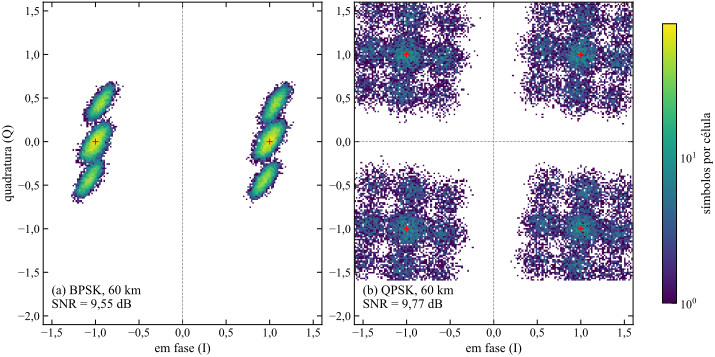

In [28]:
smf = FiberConfig(length=100e3)                                   # D = 16 ps/(nm km), 0,2 dB/km

bpsk_fiber = run(with_link(bpsk_system, [SpanConfig(smf)]), bpsk_simulation)
qpsk_fiber = run(with_link(qpsk_system, [SpanConfig(smf)]), qpsk_simulation)
report("BPSK, 60 km", bpsk_fiber)
report("QPSK, 60 km", qpsk_fiber)
show([("BPSK, 60 km", bpsk_fiber, "BPSK"), ("QPSK, 60 km", qpsk_fiber, "QPSK")])

Sem compensação, a EVM vai a 19,7 % no BPSK e 19,3 % no QPSK, contra 3,6 % sem fibra (o filtro do receptor, na seção da híbrida). No QPSK cada ponto vira um pequeno conjunto de nuvens, o valor recebido começa a depender dos símbolos vizinhos, e cada combinação de vizinhos cai num lugar. No BPSK os pontos se espalham também na quadratura, que estava vazia no BPSK, pois a dispersão é uma distorção de fase e leva parte do sinal para fora do eixo real (em fase).

O número de erros não aumenta, pois, a 10 GBd, os 60 km espalham o símbolo por menos de um período. A 60 GBd, por exemplo, a banda é 6 vezes maior e o símbolo 6 vezes mais curto, e o mesmo enlace espalharia cada símbolo por cerca de 27 símbolos.

### DCF

A fibra compensadora de dispersão aqui desfaz a dispersão de 60 km de SMF, porque a dispersão acumulada se anula: $D_1 L_1 + D_2 L_2 = 0$. A compensação acontece no próprio enlace, porém introduzimos mais perda, a DCF tem 0,5 dB/km, e a área efetiva menor (20 µm²) aumenta efeitos não lineares.

DCF: 16.0 km, 8.0 dB de perda
BPSK, SMF + DCF               : recebida = -28.00 dBm | EVM = 12.18 % | SNR = 18.29 dB | erros = 0/32704
QPSK, SMF + DCF               : recebida = -28.00 dBm | EVM =  8.29 % | SNR = 21.63 dB | erros = 0/65408


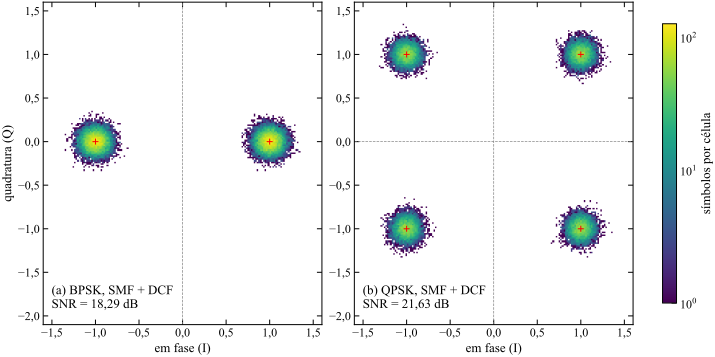

In [29]:
dcf_length = smf.length * smf.dispersion / 100e-6                # D1 L1 + D2 L2 = 0
dcf = FiberConfig(length=dcf_length, dispersion=-100e-6, attenuation=0.5e-3, effective_area=20e-12)
print(f"DCF: {dcf_length / 1e3:.1f} km, {dcf.attenuation * dcf.length:.1f} dB de perda")

bpsk_dcf = run(with_link(bpsk_system, [SpanConfig(smf), SpanConfig(dcf)]), bpsk_simulation)
qpsk_dcf = run(with_link(qpsk_system, [SpanConfig(smf), SpanConfig(dcf)]), qpsk_simulation)
report("BPSK, SMF + DCF", bpsk_dcf)
report("QPSK, SMF + DCF", qpsk_dcf)
show([("BPSK, SMF + DCF", bpsk_dcf, "BPSK"), ("QPSK, SMF + DCF", qpsk_dcf, "QPSK")])

Com a DCF a EVM volta a 3,8 % no BPSK e 4,2 % no QPSK, perto dos 3,6 % do filtro do receptor sem fibra, e as nuvens voltam a ser compactas. A potência recebida cai para −16,8 dBm, 4,8 dB abaixo da fibra sozinha. A essa potência o ruído do receptor ainda é pequeno, mas um enlace mais longo, ou com mais trechos, fica sem sinal. Por isso o EDFA.

### EDFA

O trecho agora perde 16,8 dB: 12 da SMF e 4,8 da DCF. Um EDFA no fim do trecho devolve essa perda, com ganho fixo igual a ela, e soma ruído de emissão (ASE), com figura de ruído de 5 dB (notebook 04).

ganho do EDFA = 28.0 dB
BPSK, SMF + DCF + EDFA        : recebida =   0.17 dBm | EVM =  9.35 % | SNR = 20.59 dB | erros = 0/32704
QPSK, SMF + DCF + EDFA        : recebida =   0.17 dBm | EVM =  6.48 % | SNR = 23.77 dB | erros = 0/65408


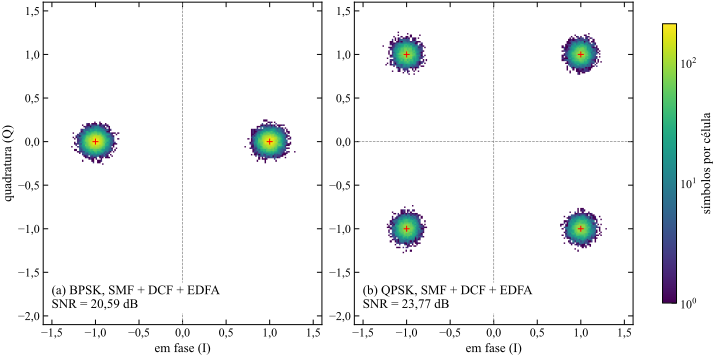

In [30]:
span_loss_db = smf.attenuation * smf.length + dcf.attenuation * dcf.length
edfa = AmplifierConfig(mode="fixed_gain", gain_db=span_loss_db, noise_figure_db=5.0)
print(f"ganho do EDFA = {span_loss_db:.1f} dB")

bpsk_edfa = run(with_link(bpsk_system, [SpanConfig(smf), SpanConfig(dcf, amplifier=edfa)]), bpsk_simulation)
qpsk_edfa = run(with_link(qpsk_system, [SpanConfig(smf), SpanConfig(dcf, amplifier=edfa)]), qpsk_simulation)
report("BPSK, SMF + DCF + EDFA", bpsk_edfa)
report("QPSK, SMF + DCF + EDFA", qpsk_edfa)
show([("BPSK, SMF + DCF + EDFA", bpsk_edfa, "BPSK"), ("QPSK, SMF + DCF + EDFA", qpsk_edfa, "QPSK")])

O EDFA devolve a potência a 0 dBm. A SNR sobe para 29,3 dB no BPSK e 29,0 dB no QPSK, um pouco acima da do passo anterior, porque o ruído do receptor fica ainda menor a 0 dBm. O ASE pesa pouco, pois na entrada do EDFA chegam −16,8 dBm, e com essa potência o ruído somado fica bem abaixo do sinal. O que sobra é a EVM de cerca de 3,5 %, ainda causada pelo filtro do receptor.

## E se o oscilador local for outro laser?

Até aqui o oscilador local era uma cópia do laser do transmissor. Na prática é outro laser, com a sua fase e com um desvio de frequência. Trocamos para `lo_source: free`, com desvio de 500 MHz (o valor do arquivo do VPI), e subimos a potência recebida para −30 dBm, para o ruído não atrapalhar a figura.

WARNING  [CoherentNeedsCarrierRecovery]
  Canal 0: oscilador local livre (rx.lo_source = 'free') e desvio de frequencia de 500 MHz, e o receptor ainda nao recupera a portadora. A constelacao gira e a BER medida nao representa o enlace.
  Sugestao: Para o homodino ideal: rx.lo_source = 'tx_laser' e rx.lo_frequency_offset = 0.
cópia do laser do transmissor: canal 0: BER contada = 0.000e+00 (0/65492) | EVM = 9.97 % (SNR = 20.03 dB) | Q = 10.032 | BER por Q = 5.506e-24 | potencia recebida = -30.00 dBm | instante = 5 amostras | simbolos 11 a 32756 | MI = 2.000, GMI = 2.000 bits/simbolo
oscilador local livre:         canal 0: BER contada = 4.928e-01 (32274/65492) | EVM = 5231.28 % (SNR = -34.37 dB) | Q = 0.019 | BER por Q = 4.924e-01 | potencia recebida = -30.00 dBm | instante = -112440 amostras | simbolos 11 a 32756 | MI = 0.001, GMI = 0.001 bits/simbolo


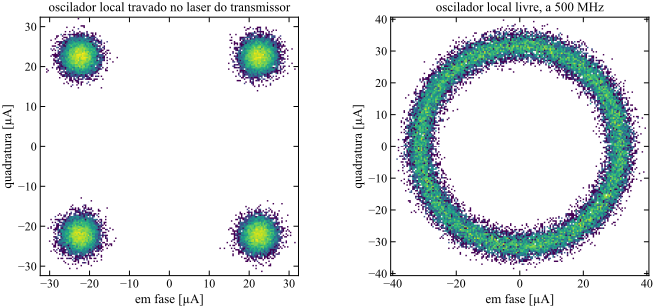

BPSK, cópia do laser do transmissor: canal 0: BER contada = 0.000e+00 (0/32746) | EVM = 9.99 % (SNR = 20.01 dB) | Q = 13.308 | BER por Q = 1.034e-40 | potencia recebida = -30.00 dBm | instante = 5 amostras | simbolos 11 a 32756 | MI = 1.000, GMI = 1.000 bits/simbolo
BPSK, oscilador local livre:         canal 0: BER contada = 4.879e-01 (15978/32746) | EVM = 4845.47 % (SNR = -33.71 dB) | Q = 0.029 | BER por Q = 4.884e-01 | potencia recebida = -30.00 dBm | instante = 115715 amostras | simbolos 11 a 32756 | MI = 0.001, GMI = 0.001 bits/simbolo


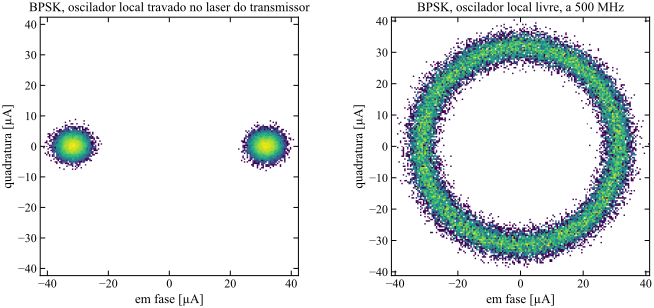

In [31]:
import dataclasses

channel = qpsk_system.channels[0]

def with_receiver(system, power_dbm, **rx_fields):
    """O mesmo sistema, com outra potência recebida e outros campos do receptor."""
    c = system.channels[0]
    c = dataclasses.replace(c, launch_power=dbm_to_w(power_dbm), rx=dataclasses.replace(c.rx, **rx_fields))
    return dataclasses.replace(system, channels=(c,))

locked = run(with_receiver(qpsk_system, -30.0), qpsk_simulation, previous=qpsk)
free = run(with_receiver(qpsk_system, -30.0, lo_source="free", lo_frequency_offset=500e6), qpsk_simulation, previous=qpsk)
for violation in free.violations:
    print(violation)
print("cópia do laser do transmissor:", locked.summary())
print("oscilador local livre:        ", free.summary())

fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
for a, result, title in ((ax[0], locked, "oscilador local travado no laser do transmissor"),
                         (ax[1], free, "oscilador local livre, a 500 MHz")):
    m = result.metrics[0]
    current = result.output("ch0.rx.frontend").samples[0]
    points = sample_symbols(current, 16, locked.metrics[0].delay, m.first_symbol, m.last_symbol)
    density_map(a, points * 1e6)
    a.set(xlabel="em fase [µA]", ylabel="quadratura [µA]", title=title, aspect="equal")
plt.tight_layout()
plt.show()

# o mesmo para o BPSK
bpsk_locked = run(with_receiver(bpsk_system, -30.0), bpsk_simulation, previous=bpsk)
bpsk_free = run(with_receiver(bpsk_system, -30.0, lo_source="free", lo_frequency_offset=500e6), bpsk_simulation, previous=bpsk)
print("BPSK, cópia do laser do transmissor:", bpsk_locked.summary())
print("BPSK, oscilador local livre:        ", bpsk_free.summary())

fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
for a, result, title in ((ax[0], bpsk_locked, "BPSK, oscilador local travado no laser do transmissor"),
                         (ax[1], bpsk_free, "BPSK, oscilador local livre, a 500 MHz")):
    m = result.metrics[0]
    current = result.output("ch0.rx.frontend").samples[0]
    points = sample_symbols(current, 16, bpsk_locked.metrics[0].delay, m.first_symbol, m.last_symbol)
    density_map(a, points * 1e6)
    a.set(xlabel="em fase [µA]", ylabel="quadratura [µA]", title=title, aspect="equal")
plt.tight_layout()
plt.show()

Com a cópia do laser do transmissor, a −30 dBm: quatro pontos, EVM de 10 % e nenhum erro. Com o oscilador local livre a constelação gira 0,05 volta por símbolo (500 MHz em 10 GBd) e vira um anel: a BER vai a 0,49. O sinal está lá, com a mesma amplitude, mas o receptor precisa estimar e desfazer essa rotação, e o ruído de fase dos dois lasers, antes de decidir. É a recuperação de portadora, feita pelo DSP da próxima seção. Sem ele, a validação avisa.

## DSP: processamento digital de sinais

O oscilador local livre mostrou o limite do receptor sem processamento: ele só sabe tirar uma rotação constante, e a fase entre dois lasers não é constante. Todo receptor coerente atual resolve isso no digital. Um conversor analógico-digital (ADC) amostra I e Q de cada polarização, e uma cadeia de algoritmos corrige o sinal antes da decisão. É o DSP, e ele faz, em ordem:

- compensa a dispersão acumulada na fibra, com um filtro que tem a resposta inversa da fibra
- acha o instante dos símbolos
- separa as polarizações, que a fibra mistura, e tira o que sobra de dispersão e de PMD, com um equalizador de 7 coeficientes por polarização
- tira o desvio de frequência entre o laser do transmissor e o oscilador local
- acompanha a fase da portadora, que anda com o ruído de fase dos dois lasers

Daqui em diante precisamos dele pelos três lados: com dois lasers a fase e a frequência do batimento mudam o tempo todo, com duas polarizações a fibra mistura X e Y na chegada, e com fibra sem DCF só o DSP compensa a dispersão.

Cada uma dessas correções é uma estimativa, e há dois jeitos de estimar. Um receptor real não sabe o que foi transmitido e estima tudo pelo próprio sinal: é o DSP cego, que fica para o notebook 10. O DSP com símbolos conhecidos (em inglês, data-aided) usa os símbolos transmitidos, que o simulador conhece:

- o instante e o desvio de frequência saem da correlação entre o sinal recebido e os símbolos transmitidos
- a matriz de polarização e a fase saem de mínimos quadrados contra os símbolos, em blocos de 64 símbolos, e a fase é refinada símbolo a símbolo com uma média móvel de 21 símbolos
- o equalizador é o de mínimos quadrados contra os símbolos

Num sistema real isso equivale a mandar só sequências de treinamento. Usamos o DSP com símbolos conhecidos porque ele mede a física do enlace sem depender da convergência de um algoritmo: se a constelação piora, foi o enlace, e não o DSP que se perdeu. No simcopy ele entra com `rx.dsp` na configuração, e `mode: data_aided` é o padrão. Neste modo não há ADC: as estimativas são feitas direto no sinal simulado.

### Oscilador local livre, com DSP

O mesmo caso da seção anterior: −30 dBm no receptor, oscilador local livre a 500 MHz, agora com o DSP. Sem fibra, a compensação de dispersão não tem o que fazer.

BPSK, oscilador local livre   : recebida = -30.00 dBm | EVM =  8.40 % | SNR = 21.51 dB | erros = 0/32746
QPSK, oscilador local livre   : recebida = -30.00 dBm | EVM =  8.39 % | SNR = 21.53 dB | erros = 0/65492


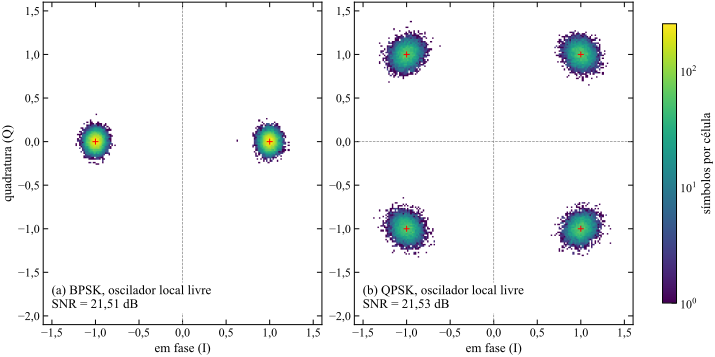

In [32]:
two_lasers = dict(lo_source="free", lo_frequency_offset=500e6, dsp=DSPConfig())   # dois lasers e o DSP

bpsk_lo = run(with_link(bpsk_system, [], -30.0, **two_lasers), bpsk_simulation)
qpsk_lo = run(with_link(qpsk_system, [], -30.0, **two_lasers), qpsk_simulation)
report("BPSK, oscilador local livre", bpsk_lo)
report("QPSK, oscilador local livre", qpsk_lo)
show([("BPSK, oscilador local livre", bpsk_lo, "BPSK"), ("QPSK, oscilador local livre", qpsk_lo, "QPSK")])

Com o DSP, o oscilador local livre volta a dar quatro pontos no QPSK e dois no BPSK, sem erros e com SNR de 21,5 dB. É até mais que os 20,0 dB da cópia do laser sem DSP, na seção anterior: o equalizador também desfaz a interferência que o filtro do receptor deixa entre os símbolos, e o ruído de fase dos lasers de 500 kHz pesa pouco a 10 GBd. As nuvens são redondas, porque a −30 dBm quem limita é o ruído do receptor.

### Uma polarização com fibra

Agora os 60 km de SMF, com os dois lasers. Precisamos do DSP por dois motivos. O primeiro é o oscilador local livre, como no passo anterior. O segundo é a dispersão: sem DCF, só o DSP a compensa. O bloco `rx.cd` aplica, na frequência, um filtro com a resposta inversa da fibra, calculada com a dispersão acumulada, que o simulador sabe pelo comprimento e pela dispersão da fibra. Na seção sem DSP, a mesma fibra deixou a EVM em 19,7 %, e foi preciso a DCF, com 4,8 dB a mais de perda. Com 0 dBm de lançamento, chegam −12 dBm.

BPSK, 60 km, com DSP          : recebida = -20.00 dBm | EVM =  5.48 % | SNR = 25.23 dB | erros = 0/32724
QPSK, 60 km, com DSP          : recebida = -20.00 dBm | EVM =  4.80 % | SNR = 26.37 dB | erros = 0/65448


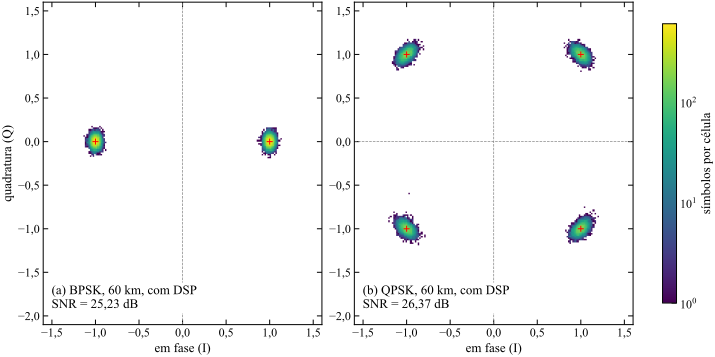

In [33]:
bpsk_fiber_dsp = run(with_link(bpsk_system, [SpanConfig(smf)], **two_lasers), bpsk_simulation)
qpsk_fiber_dsp = run(with_link(qpsk_system, [SpanConfig(smf)], **two_lasers), qpsk_simulation)
report("BPSK, 60 km, com DSP", bpsk_fiber_dsp)
report("QPSK, 60 km, com DSP", qpsk_fiber_dsp)
show([("BPSK, 60 km, com DSP", bpsk_fiber_dsp, "BPSK"), ("QPSK, 60 km, com DSP", qpsk_fiber_dsp, "QPSK")])

Com o DSP, os 60 km dão 28,3 dB no BPSK e 28,2 dB no QPSK, com EVM de 3,9 %. A constelação volta a ser compacta sem a DCF, e chegam −12 dBm em vez de −16,8. Os pontos se alongam na direção tangencial: a −12 dBm o ruído do receptor já é pequeno, e o que sobra é o ruído de fase dos dois lasers, que a média de 21 símbolos não acompanha por inteiro.

### Uma polarização com fibra e EDFA

Com a dispersão compensada no DSP, a DCF deixa de ser necessária, e o trecho fica só com a SMF e o EDFA, que devolve os 12 dB da SMF. O DSP continua necessário pelos mesmos dois motivos: o oscilador local livre e a dispersão, que agora não tem DCF nenhuma para desfazê-la dentro do enlace.

ganho do EDFA = 20.0 dB
BPSK, SMF + EDFA, com DSP     : recebida =   0.03 dBm | EVM =  4.75 % | SNR = 26.47 dB | erros = 0/32724
QPSK, SMF + EDFA, com DSP     : recebida =   0.03 dBm | EVM =  4.31 % | SNR = 27.32 dB | erros = 0/65448


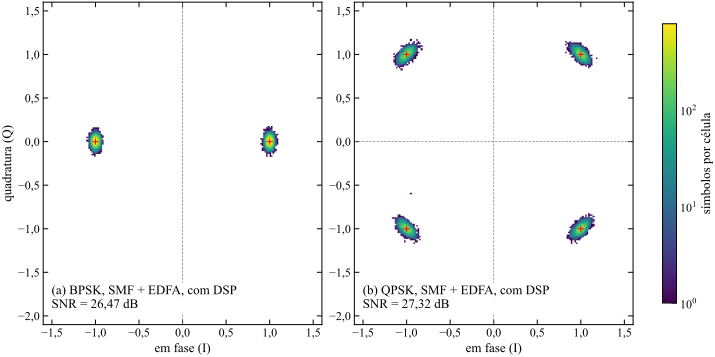

In [34]:
edfa_smf = AmplifierConfig(mode="fixed_gain", gain_db=smf.attenuation * smf.length, noise_figure_db=5.0)
print(f"ganho do EDFA = {edfa_smf.gain_db:.1f} dB")

bpsk_edfa_dsp = run(with_link(bpsk_system, [SpanConfig(smf, amplifier=edfa_smf)], **two_lasers), bpsk_simulation)
qpsk_edfa_dsp = run(with_link(qpsk_system, [SpanConfig(smf, amplifier=edfa_smf)], **two_lasers), qpsk_simulation)
report("BPSK, SMF + EDFA, com DSP", bpsk_edfa_dsp)
report("QPSK, SMF + EDFA, com DSP", qpsk_edfa_dsp)
show([("BPSK, SMF + EDFA, com DSP", bpsk_edfa_dsp, "BPSK"), ("QPSK, SMF + EDFA, com DSP", qpsk_edfa_dsp, "QPSK")])

O EDFA devolve a potência a 0 dBm, e a SNR sobe só um pouco, para 28,6 dB nas duas modulações: a potência já era alta e o ruído do receptor já era pequeno. A ASE pesa pouco, porque chegam −12 dBm na entrada do EDFA. É a forma do enlace sem compensação óptica, como o do cenário do VPI: fibra e amplificador, com a dispersão toda compensada no DSP.

### Duas polarizações

Com duas polarizações, o transmissor divide o laser entre X e Y, e cada metade passa pelo seu modulador IQ: são dois sinais independentes, o dobro de bits na mesma banda. O receptor divide o sinal e o oscilador local entre X e Y, com uma híbrida e quatro fotodetectores por polarização. Ao longo da fibra a polarização gira, e na chegada X e Y estão misturados: é o DSP que acha a matriz que os separa. Sem fibra ainda não há mistura, e começamos por aí.

No simcopy é `pol: DP`, que pede `rx.dsp`. A potência é a soma das duas polarizações: com os mesmos −30 dBm, cada uma recebe metade.

Nas figuras, X (em azul) e Y (em vermelho) aparecem no mesmo plano, com Y girada de 90° no BPSK e de 45° no QPSK, só para não cair sobre X. O giro é só do desenho: a medida usa as duas como chegam. O rótulo de cada painel traz a SNR de cada uma.

BPSK, duas polarizações       : recebida = -30.00 dBm | EVM = 13.81 % | SNR = 17.19 dB | erros = 0/65492
QPSK, duas polarizações       : recebida = -30.00 dBm | EVM = 13.81 % | SNR = 17.20 dB | erros = 0/130984


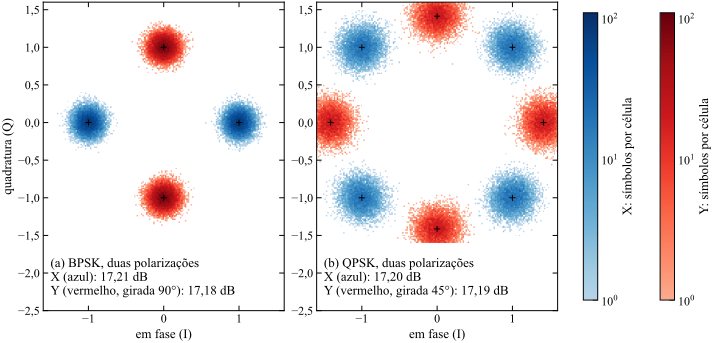

In [35]:
def dual(system):
    """O mesmo sistema com duas polarizações."""
    return dataclasses.replace(system, channels=(dataclasses.replace(system.channels[0], pol=Pol.DP),))

bpsk_dp = run(with_link(dual(bpsk_system), [], -30.0, **two_lasers), bpsk_simulation)
qpsk_dp = run(with_link(dual(qpsk_system), [], -30.0, **two_lasers), qpsk_simulation)
report("BPSK, duas polarizações", bpsk_dp)
report("QPSK, duas polarizações", qpsk_dp)
show([("BPSK, duas polarizações", bpsk_dp, "BPSK"), ("QPSK, duas polarizações", qpsk_dp, "QPSK")])

Com duas polarizações e os mesmos −30 dBm, a SNR cai de 21,5 para 17,2 dB. Cada polarização recebe metade do sinal e metade do oscilador local, então o batimento cai 6 dB. O ruído de disparo, que vem do oscilador local, cai 3 dB, e o ruído térmico dos fotodetectores não muda. A soma cai entre 3 e 6 dB, aqui 4,3 dB. Em troca, o canal leva o dobro de bits: 20 Gb/s no BPSK e 40 Gb/s no QPSK.

### Duas polarizações com fibra

Os mesmos 60 km do passo com uma polarização, agora com duas. Ao longo da fibra a polarização gira, e a PMD atrasa uma polarização em relação à outra. Além de compensar a dispersão, o DSP desfaz as duas coisas com a matriz de polarização e o equalizador.

BPSK, duas polarizações, 60 km: recebida = -20.00 dBm | EVM =  5.51 % | SNR = 25.17 dB | erros = 0/65448
QPSK, duas polarizações, 60 km: recebida = -20.00 dBm | EVM =  5.50 % | SNR = 25.20 dB | erros = 0/130896


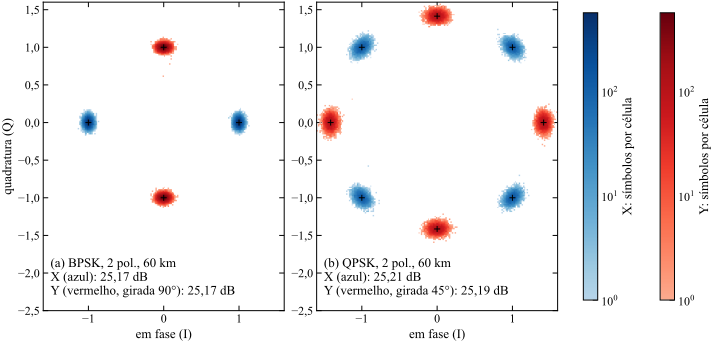

In [36]:
bpsk_dp_fiber = run(with_link(dual(bpsk_system), [SpanConfig(smf)], **two_lasers), bpsk_simulation)
qpsk_dp_fiber = run(with_link(dual(qpsk_system), [SpanConfig(smf)], **two_lasers), qpsk_simulation)
report("BPSK, duas polarizações, 60 km", bpsk_dp_fiber)
report("QPSK, duas polarizações, 60 km", qpsk_dp_fiber)
show([("BPSK, 2 pol., 60 km", bpsk_dp_fiber, "BPSK"), ("QPSK, 2 pol., 60 km", qpsk_dp_fiber, "QPSK")])

Com duas polarizações e 60 km, a SNR fica em 28,3 dB nas duas, a mesma de uma polarização. A −12 dBm cada polarização ainda tem potência de sobra, e quem limita é o ruído de fase dos lasers, que é o mesmo nas duas. Além da dispersão, aqui o DSP desfaz a rotação de polarização e a PMD da fibra: X e Y saem separadas, com SNR quase igual.

### Duas polarizações com SMF + DCF + EDFA

O enlace da seção sem DSP, agora com duas polarizações e dois lasers. A DCF já desfaz a dispersão dentro do enlace, e a compensação do DSP fica sem trabalho, porque a dispersão acumulada é zero.

BPSK, 2 pol., SMF + DCF + EDFA: recebida =   0.18 dBm | EVM =  7.32 % | SNR = 22.71 dB | erros = 0/65408
QPSK, 2 pol., SMF + DCF + EDFA: recebida =   0.18 dBm | EVM =  7.32 % | SNR = 22.71 dB | erros = 0/130816


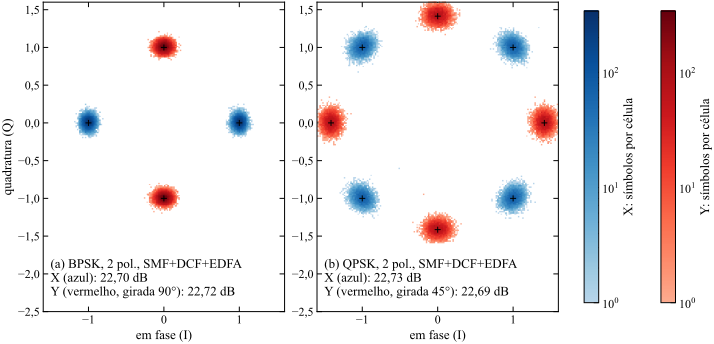

In [37]:
link = [SpanConfig(smf), SpanConfig(dcf, amplifier=edfa)]
bpsk_dp_edfa = run(with_link(dual(bpsk_system), link, **two_lasers), bpsk_simulation)
qpsk_dp_edfa = run(with_link(dual(qpsk_system), link, **two_lasers), qpsk_simulation)
report("BPSK, 2 pol., SMF + DCF + EDFA", bpsk_dp_edfa)
report("QPSK, 2 pol., SMF + DCF + EDFA", qpsk_dp_edfa)
show([("BPSK, 2 pol., SMF+DCF+EDFA", bpsk_dp_edfa, "BPSK"), ("QPSK, 2 pol., SMF+DCF+EDFA", qpsk_dp_edfa, "QPSK")])

Com a DCF e o EDFA a SNR fica em 28,1 e 28,2 dB, 0,1 a 0,2 dB abaixo dos 60 km com a compensação no DSP: é a ASE do EDFA. Os dois caminhos chegam ao mesmo lugar. Com DSP a DCF deixa de ser necessária, e ela ainda soma perda e, pela área efetiva menor, não linearidade. Para a ASE pesar, é preciso lançar menos potência ou somar trechos, como na varredura do notebook 07.